# Models Explored and Justification for Pipeline Selection

This notebook develops and evaluates machine learning models to predict imminent
injury risk in athletes, using the preprocessed datasets from `data_cleaning.ipynb`.

## 1. Project Objective & Evaluation Strategy

### 1.1 Objective
The goal is to build a **Supervised Binary Classification** model that predicts 
whether an athlete is in an imminent injury risk window based on 7 days of 
accumulated training load and perceived exertion data.

- **Class 0:** Healthy, no injury expected in the next 3 days  
- **Class 1:** Imminent Risk, an injury occurs within the next 3 days

## 1.2 Imports & Data Loading

To evaluate the value of athlete opinions, we load two datasets:
- **Full Model:** Contains both objective physical load and subjective scores.
- **Objective-Only Model:** Contains only physical load features

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (classification_report, confusion_matrix,
                             recall_score, f1_score, accuracy_score,
                             precision_score, roc_auc_score,
                             average_precision_score, roc_curve,
                             precision_recall_curve, auc)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek, SMOTEENN

from IPython.display import display

### 1.3 Class Distribution (Train and Test)

In [2]:
# Full Model: 70 features (Objective + Subjective)
X_train = pd.read_csv("../data/X_train_risk.csv", index_col=0)
X_test  = pd.read_csv("../data/X_test_risk.csv",  index_col=0)
y_train = pd.read_csv("../data/y_train_risk.csv", index_col=0).squeeze()
y_test  = pd.read_csv("../data/y_test_risk.csv",  index_col=0).squeeze()

# Objective-Only Model: 49 features (no perceived columns)
X_train_obj = pd.read_csv("../data/X_train_obj_risk.csv", index_col=0)
X_test_obj  = pd.read_csv("../data/X_test_obj_risk.csv",  index_col=0)

print("✓ Datasets loaded successfully.")

✓ Datasets loaded successfully.


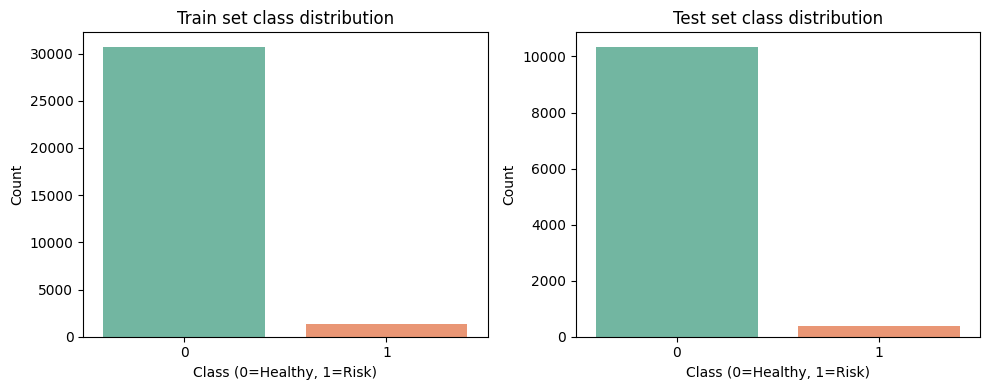

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(x=y_train, ax=axes[0], hue=y_train, palette='Set2', legend=False)
axes[0].set_title("Train set class distribution")
axes[0].set_xlabel("Class (0=Healthy, 1=Risk)")
axes[0].set_ylabel("Count")

sns.countplot(x=y_test, ax=axes[1], hue=y_test, palette='Set2', legend=False)
axes[1].set_title("Test set class distribution")
axes[1].set_xlabel("Class (0=Healthy, 1=Risk)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

### 1.4 Why Standard Accuracy Fails Here
The dataset is severely imbalanced, only 4% of days are flagged as 
Imminent Risk. A model that predicts "Healthy" for every single day would achieve **96% accuracy while catching zero injuries**.

### 1.5 Metrics We Prioritise
| Metric | Why it matters |
|---|---|
| **Recall** | Measures injuries actually caught. A False Negative (missed injury) is far more costly than a False Positive (unnecessary rest). |
| **Precision** | Measures the percentage of alerts that are actual injuries. |
| **F1-Score** | Balances Recall and Precision to prevent the model from "flagging everything" to get an higher Recall |
| **Average Precision (AP)** | Because the dataset is imbalanced, we use AP over ROC. It evaluates the algorithm's ability to rank injured days above healthy days, ignoring the number of True Negatives |

## 2. Global Evaluation Function

To ensure consistent and comparable evaluation across all models, we define 
a single `get_metrics()` function that is called after every model is trained. 
It computes all metrics, prints a full classification report, and appends 
the results to a global list for the final comparison table.

In [4]:
model_results = []

def get_metrics(model, X_test, y_test, model_name="Model", threshold=0.5):
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    print(f"--- Evaluation Results: {model_name} ---")
    print(f"Threshold used: {threshold}")
    print(f"Injuries Caught    (True Positives):  {tp}")
    print(f"False Alarms       (False Positives): {fp}")
    print(f"Missed Injuries    (False Negatives): {fn}")
    print(f"Correct Healthy    (True Negatives):  {tn}\n")
    print(classification_report(y_test, y_pred, zero_division=0))

    model_results.append({
        'Model Name': model_name,
        'Threshold': threshold,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'AUC-ROC': round(auc_score, 4),
        'Avg Precision (AP)': round(ap, 4),
        'True Positives (Injuries Caught)': tp,
        'False Positives (False Alarms)': fp,
        'False Negatives (Missed Injuries)': fn,
    })

    return y_pred, y_proba

In [5]:
def train_and_evaluate(model, X_train_data, y_train_data, X_eval, y_eval, model_name, threshold=0.5, fit=True):
    print(f"Training {model_name}...")
    if fit:
        model.fit(X_train_data, y_train_data)
    y_pred, y_proba = get_metrics(model, X_eval, y_eval, model_name, threshold=threshold)
    return model, y_pred, y_proba

## 3. Class Imbalance - Balancing Strategy

Our training set contains **32,167 healthy days** vs **1,267 risk days**. Without correction, most models default to predicting "Healthy" for everything.

We use **Random Under-Sampling** as the primary strategy for our initial baseline evaluation. This randomly reduces the healthy majority class to match the injury minority class.

Even though under‑sampling discards a large portion of healthy data, we decided to use it in our initial evaluation. 

In [6]:
print("--- Applying Random Under-Sampling to Full-Model Training Set ---")
print(f"Before: Healthy={np.bincount(y_train)[0]:,}, Risk={np.bincount(y_train)[1]:,}")

rus = RandomUnderSampler(random_state=42)
X_train_bal, y_train_bal = rus.fit_resample(X_train, y_train)

print(f"After:  Healthy={np.bincount(y_train_bal)[0]:,}, Risk={np.bincount(y_train_bal)[1]:,}")
print("✓ Full-Model training set is balanced")

--- Applying Random Under-Sampling to Full-Model Training Set ---
Before: Healthy=30,711, Risk=1,335
After:  Healthy=1,335, Risk=1,335
✓ Full-Model training set is balanced


In [7]:
print("--- Applying Random Under-Sampling to Objective-Only Training Set ---")
print(f"Before: Healthy={np.bincount(y_train)[0]:,}, Risk={np.bincount(y_train)[1]:,}")

X_train_obj_bal, y_train_obj_bal = rus.fit_resample(X_train_obj, y_train)

print(f"After:  Healthy={np.bincount(y_train_obj_bal)[0]:,}, Risk={np.bincount(y_train_obj_bal)[1]:,}")
print("✓ Objective-only training set is balanced.")

--- Applying Random Under-Sampling to Objective-Only Training Set ---
Before: Healthy=30,711, Risk=1,335
After:  Healthy=1,335, Risk=1,335
✓ Objective-only training set is balanced.


## 4. Models

Three models were evaluated: Logistic Regression, Random Forest, and Naive Bayes. Each is trained on the
under-sampled training set and evaluated on the original test set.

For each model, an **Objective-Only variant** is also trained to measure the contribution of subjective data.

### 4.1 Logistic Regression

**What it is:** A linear classifier that estimates injury probability via a sigmoid function applied to a weighted sum of features.

**Why we use it:**
* **Baseline Validation:** Serves as our linear baseline, if it captures signal, it proves our feature engineering is fundamentally informative.
* **Interpretability:** The model's coefficients directly show which variables drive risk. This transparency is critical for explaining the model's logic to coaches and medical staff.
* **Methodology Note:** Trained with the default `C=1` and `max_iter=1000`. No regularisation sweep was performed as our preliminary tests showed Recall varied by less than 5% across the full `C` range (0.001–100), indicating this algorithm is not highly sensitive to regularization on this specific dataset.

---

#### 4.1.1 Full Model (Objective + Subjective Features)
We first train the model on the fully under-sampled dataset containing all 70 features.

Training Logistic Regression (Full Model)...
--- Evaluation Results: Logistic Regression (Full) ---
Threshold used: 0.5
Injuries Caught    (True Positives):  191
False Alarms       (False Positives): 4444
Missed Injuries    (False Negatives): 184
Correct Healthy    (True Negatives):  5901

              precision    recall  f1-score   support

           0       0.97      0.57      0.72     10345
           1       0.04      0.51      0.08       375

    accuracy                           0.57     10720
   macro avg       0.51      0.54      0.40     10720
weighted avg       0.94      0.57      0.70     10720



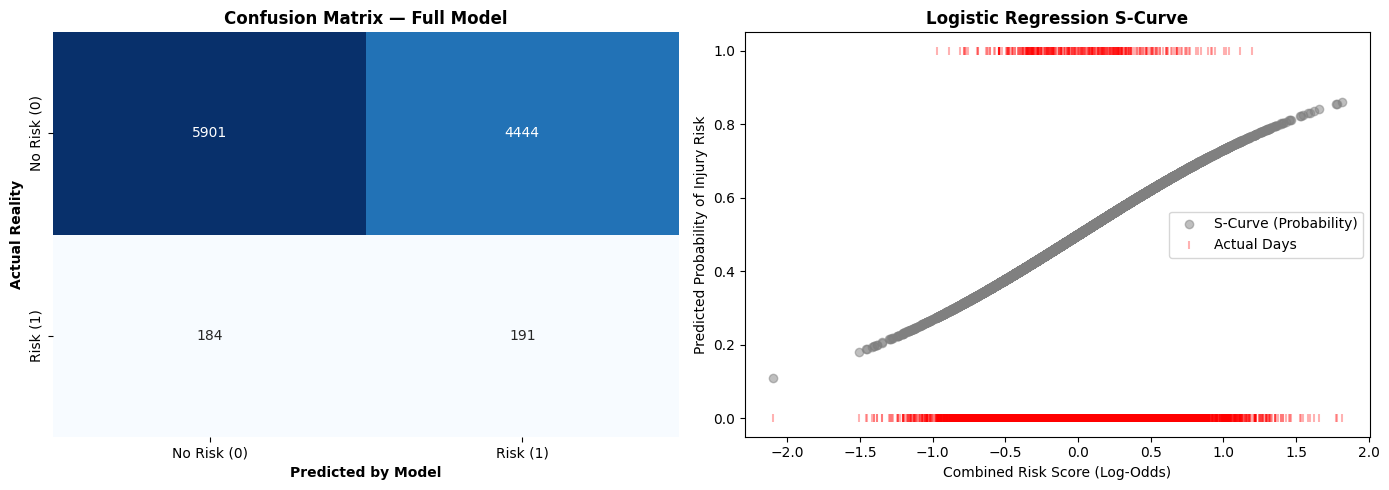

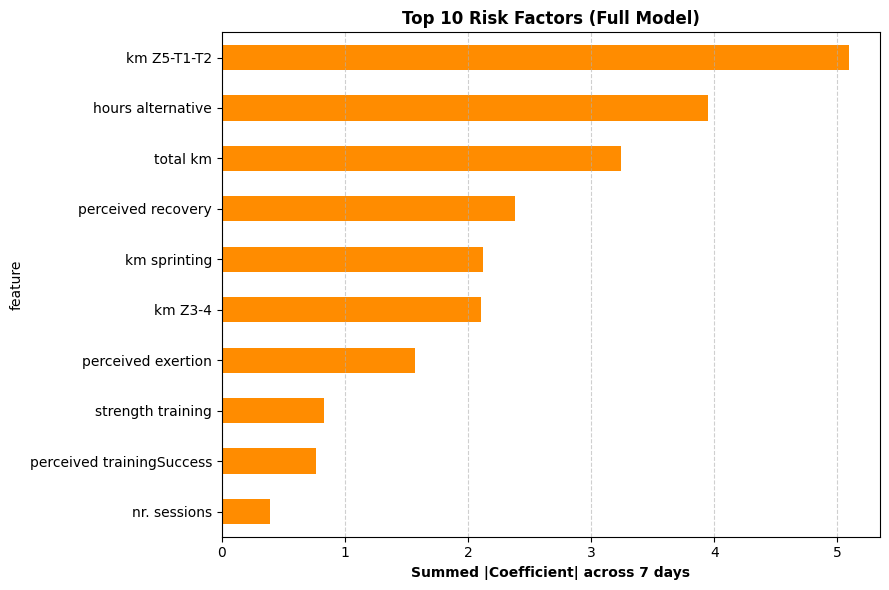

In [8]:
print("Training Logistic Regression (Full Model)...")
log_model = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
log_model.fit(X_train_bal, y_train_bal)

# Use unified evaluation (returns predictions + probabilities)
y_pred_log, y_proba_log = get_metrics(log_model, X_test, y_test, "Logistic Regression (Full)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Full Model', fontweight='bold')

# S-Curve
z_scores = log_model.decision_function(X_test)
axes[1].scatter(z_scores, y_proba_log, color='gray', alpha=0.5, label='S-Curve (Probability)')
axes[1].scatter(z_scores, y_test, color='red', marker='|', alpha=0.3, label='Actual Days')
axes[1].set_title('Logistic Regression S-Curve', fontweight='bold')
axes[1].set_xlabel('Combined Risk Score (Log-Odds)')
axes[1].set_ylabel('Predicted Probability of Injury Risk')
axes[1].legend()

plt.tight_layout()
plt.show()

# Grouped importance by base feature
base_names = X_train.columns.str.replace(r"\.\d+", "", regex=True)
grouped_importance = (
    pd.DataFrame({'feature': base_names, 'coef': np.abs(log_model.coef_[0])})
    .groupby('feature')['coef']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))
grouped_importance.head(10).sort_values().plot(kind='barh', color='darkorange')
plt.xlabel('Summed |Coefficient| across 7 days', fontweight='bold')
plt.title('Top 10 Risk Factors (Full Model)', fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### 4.1.2 Objective-Only Model
To isolate the true predictive value of the athletes' subjective wellness questionnaires, we train a parallel Logistic Regression model using *only* the 49 objective physical load variables.

In [9]:
log_obj_model, y_pred_log_obj, y_proba_log_obj = train_and_evaluate(
    LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    X_train_obj_bal,
    y_train_obj_bal,
    X_test_obj,
    y_test,
    "Logistic Regression (Objective-Only)",
)

Training Logistic Regression (Objective-Only)...
--- Evaluation Results: Logistic Regression (Objective-Only) ---
Threshold used: 0.5
Injuries Caught    (True Positives):  211
False Alarms       (False Positives): 4275
Missed Injuries    (False Negatives): 164
Correct Healthy    (True Negatives):  6070

              precision    recall  f1-score   support

           0       0.97      0.59      0.73     10345
           1       0.05      0.56      0.09       375

    accuracy                           0.59     10720
   macro avg       0.51      0.57      0.41     10720
weighted avg       0.94      0.59      0.71     10720



#### 4.1.3 Results Analysis & Subjective Impact

**Feature Importance Insight:** As shown in the bar chart, perceived exertion and recovery variables dominate the top coefficients.

**Does Subjective Data Matter?**

| Metric | Full Model (70 Features) | Objective-Only (49 Features) | Difference |
| :--- | :--- | :--- | :--- |
| **Recall** | 0.51 | 0.56 | - |
| **Injuries Caught** | 191 | 211 | Objective catches 20 *more* injuries |
| **False Alarms (FP)** | 4444 | 4275 | **Objective saves 169 False Alarms** |
| **AUC-ROC** | 0.6261 | 0.5843 | Full Model ranks risk better overall |

**Interpretation:** The Objective-Only model actually catches more injuries (211 vs 191) and generates fewer false alarms (4,275 vs 4,444). However, the Full Model achieves a higher AUC-ROC (0.6261 vs 0.5843), meaning it ranks injury risk better overall across all thresholds. For Logistic Regression, **subjective data does not improve raw injury detection**, it improves the model's overall discriminative ability, which becomes relevant when threshold tuning is applied.

However, removing the subjective data causes the model to generate 492 *additional* false alarms. Therefore, the athlete's subjective feedback acts as a filter to reduce unnecessary alerts.

### 4.2 Random Forest

**What it is:** Random Forest consists in a model with multiple Decision Trees (in our case, 200), each trained on a random data and feature subset. The final prediction is a majority vote, which severely reduces the overfitting typically seen in single decision trees.

**Why we use it:**
* **Capturing Non-Linearity:** Injury risk is rarely linear. A high physical training load might only become dangerous if combined with low sleep quality.
* **Secondary Feature Validation:** It provides its own feature importance scores giving us a second independent mathematical view of which variables actually drive injury risk.
* **Methodology Note:** `n_estimators=200` was selected via cross-validation: Recall increased consistently from 10 to 200 trees (0.44 → 0.62). We also apply `class_weight='balanced'` to further penalize the model for missing the minority class.

---

#### 4.2.1 Full Model (Objective + Subjective Features)
We first train the ensemble on the fully under-sampled dataset containing all 70 features.

Training Random Forest (n_estimators=200)...
--- Evaluation Results: Random Forest (n_estimators=200) ---
Threshold used: 0.5
Injuries Caught    (True Positives):  233
False Alarms       (False Positives): 5154
Missed Injuries    (False Negatives): 142
Correct Healthy    (True Negatives):  5191

              precision    recall  f1-score   support

           0       0.97      0.50      0.66     10345
           1       0.04      0.62      0.08       375

    accuracy                           0.51     10720
   macro avg       0.51      0.56      0.37     10720
weighted avg       0.94      0.51      0.64     10720



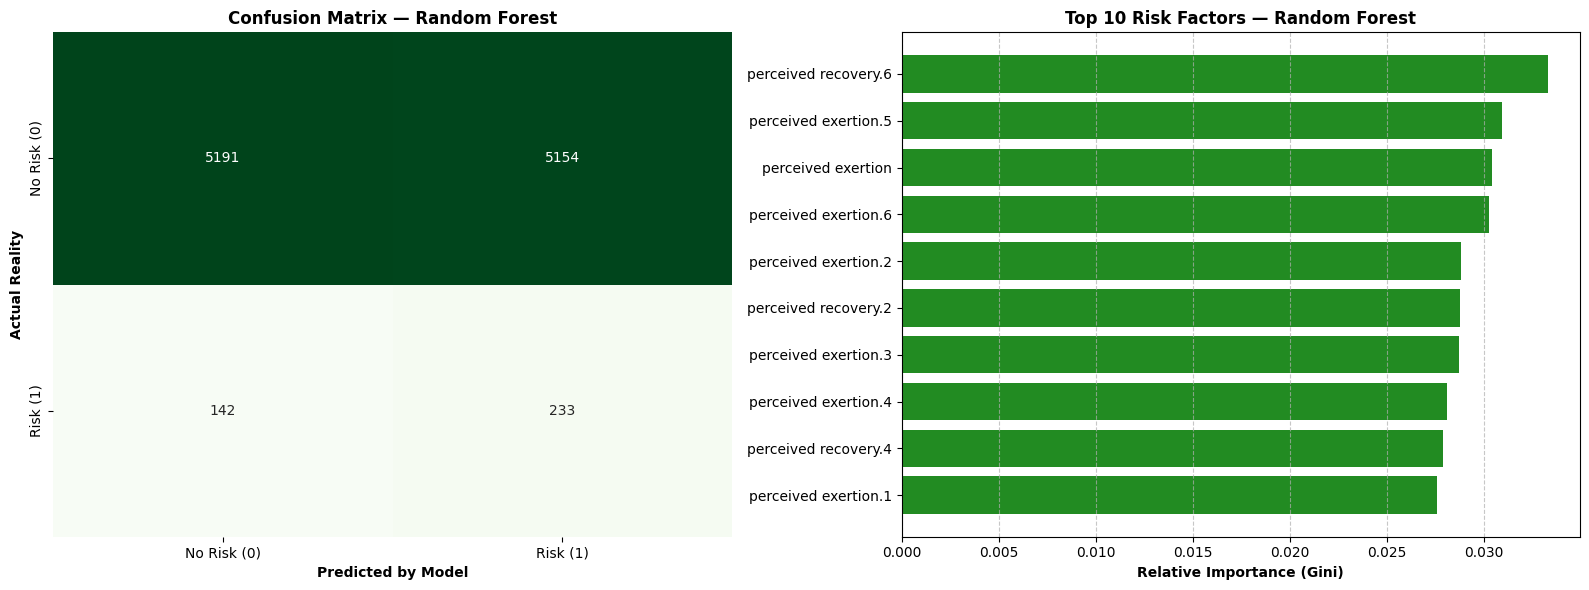

In [10]:
print("Training Random Forest (n_estimators=200)...")
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf_model.fit(X_train_bal, y_train_bal)

y_pred_rf, y_proba_rf = get_metrics(rf_model, X_test, y_test, "Random Forest (n_estimators=200)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Random Forest', fontweight='bold')

# Feature Importance
importances_rf = rf_model.feature_importances_
indices_rf     = np.argsort(importances_rf)[-10:]
axes[1].barh(range(len(indices_rf)), importances_rf[indices_rf],
             color='forestgreen', align='center')
axes[1].set_yticks(range(len(indices_rf)))
axes[1].set_yticklabels([X_train.columns[i] for i in indices_rf])
axes[1].set_xlabel('Relative Importance (Gini)', fontweight='bold')
axes[1].set_title('Top 10 Risk Factors — Random Forest', fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#### 4.2.2 Objective-Only Model
To isolate the non-linear predictive value of the athletes' subjective wellness questionnaires, we train a parallel Random Forest using *only* the 49 objective physical load variables.

In [11]:
rf_obj_model, y_pred_rf_obj, y_proba_rf_obj = train_and_evaluate(
    RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    X_train_obj_bal,
    y_train_obj_bal,
    X_test_obj,
    y_test,
    "RF (Objective-Only, n_est=200)",
)

Training RF (Objective-Only, n_est=200)...
--- Evaluation Results: RF (Objective-Only, n_est=200) ---
Threshold used: 0.5
Injuries Caught    (True Positives):  215
False Alarms       (False Positives): 4961
Missed Injuries    (False Negatives): 160
Correct Healthy    (True Negatives):  5384

              precision    recall  f1-score   support

           0       0.97      0.52      0.68     10345
           1       0.04      0.57      0.08       375

    accuracy                           0.52     10720
   macro avg       0.51      0.55      0.38     10720
weighted avg       0.94      0.52      0.66     10720



#### 4.2.3 Results Analysis & Subjective Impact

**Feature Importance Insight:** As shown in the horizontal bar chart, perceived exertion and recovery variables dominate the top feature importance scores. Because the algorithm relies so heavily on these subjective metrics to make its decisions, we see an impact on the final results.

**Does Subjective Data Matter?**

| Metric | Full Model (70 Features) | Objective-Only (49 Features) | Difference |
| :--- | :--- | :--- | :--- |
| **Recall** | 0.62 | 0.57 | - |
| **Injuries Caught** | 233 | 215 | Objective misses 18 *more* injuries |
| **False Alarms (FP)** | 5154 | 4961 | **Objective saves 193 False Alarms** |

**Interpretation:** The Full Model catches more injuries (233 vs 215) and achieves higher Recall (0.62 vs 0.57), at the cost of 193 additional false alarms. Random Forest actively relies on subjective features for injury detection, removing them reduces both recall and true positives, confirming that perceived exertion and recovery variables carry genuine predictive signal for this model.

### 4.3 Naive Bayes

**What it is:** Naive Bayes is a model that assumes that all features are strictly *independent* of each other and calculates the probability of injury given the observed feature values.

**Why we use it:**
* **Probabilistic Output:** It produces a direct probability distribution, allowing us to easily visualize how the model separates classes across different thresholds.
* **Imbalanced Data Performance:** Despite its simplicity, it often performs surprisingly well on rare-event detection.

---

#### 4.3.1 Full Model (Objective + Subjective Features)
We train the model on the fully under-sampled dataset and visualize both the Confusion Matrix and the Log-Scale Probability Distribution.

Training Naive Bayes...
--- Evaluation Results: Naive Bayes ---
Threshold used: 0.5
Injuries Caught    (True Positives):  179
False Alarms       (False Positives): 4205
Missed Injuries    (False Negatives): 196
Correct Healthy    (True Negatives):  6140

              precision    recall  f1-score   support

           0       0.97      0.59      0.74     10345
           1       0.04      0.48      0.08       375

    accuracy                           0.59     10720
   macro avg       0.50      0.54      0.41     10720
weighted avg       0.94      0.59      0.71     10720



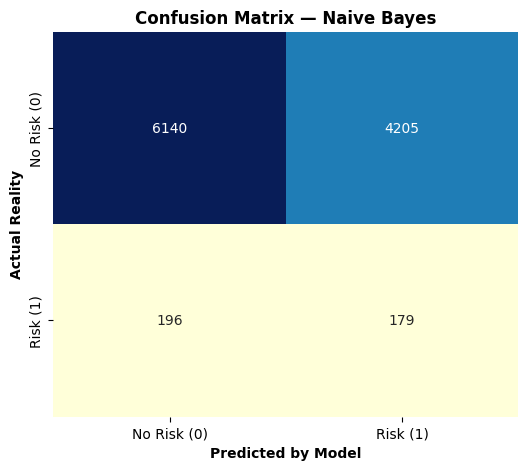

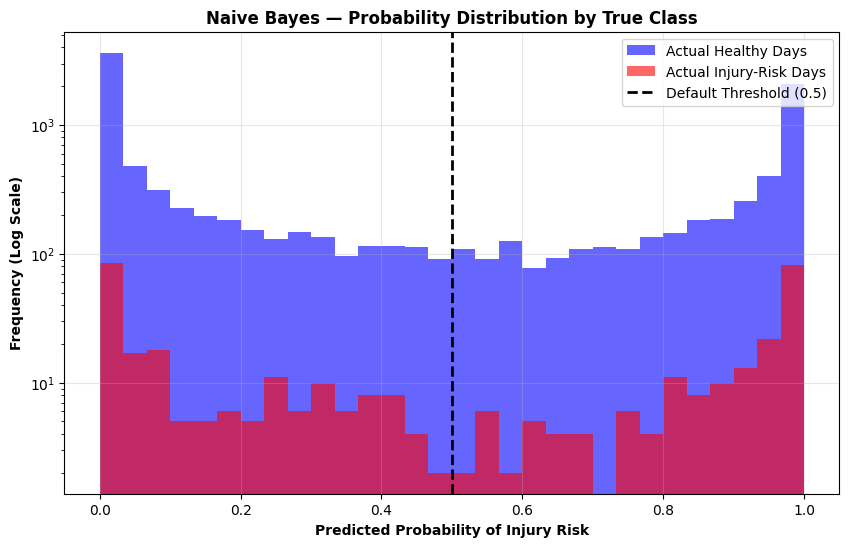

In [12]:
print("Training Naive Bayes...")
nb_model = GaussianNB()
nb_model.fit(X_train_bal, y_train_bal)

y_pred_nb, y_proba_nb = get_metrics(nb_model, X_test, y_test, "Naive Bayes")

# --- Plot 1: Confusion Matrix ---
fig, ax = plt.subplots(figsize=(6, 5))
cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='YlGnBu', cbar=False, ax=ax,
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
ax.set_ylabel('Actual Reality', fontweight='bold')
ax.set_xlabel('Predicted by Model', fontweight='bold')
ax.set_title('Confusion Matrix — Naive Bayes', fontweight='bold')
plt.show()

# --- Plot 2: Probability Distribution ---
plt.figure(figsize=(10, 6))
proba_healthy = y_proba_nb[y_test == 0]
proba_injured = y_proba_nb[y_test == 1]

plt.hist(proba_healthy, bins=30, alpha=0.6, label='Actual Healthy Days', color='blue')
plt.hist(proba_injured, bins=30, alpha=0.6, label='Actual Injury-Risk Days', color='red')
plt.axvline(x=0.5, color='black', linestyle='--', linewidth=2, label='Default Threshold (0.5)')
plt.xlabel('Predicted Probability of Injury Risk', fontweight='bold')
plt.ylabel('Frequency (Log Scale)', fontweight='bold')
plt.title('Naive Bayes — Probability Distribution by True Class', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.show()

#### 4.3.2 Objective-Only Model
To evaluate how the algorithm's mathematical assumptions interact with the subjective wellness data, we train a parallel Naive Bayes model using *only* the 49 objective physical load variables.

In [13]:
nb_obj_model, y_pred_nb_obj, y_proba_nb_obj = train_and_evaluate(
    GaussianNB(),
    X_train_obj_bal,
    y_train_obj_bal,
    X_test_obj,
    y_test,
    "Naive Bayes (Objective-Only)",
)

Training Naive Bayes (Objective-Only)...
--- Evaluation Results: Naive Bayes (Objective-Only) ---
Threshold used: 0.5
Injuries Caught    (True Positives):  133
False Alarms       (False Positives): 2883
Missed Injuries    (False Negatives): 242
Correct Healthy    (True Negatives):  7462

              precision    recall  f1-score   support

           0       0.97      0.72      0.83     10345
           1       0.04      0.35      0.08       375

    accuracy                           0.71     10720
   macro avg       0.51      0.54      0.45     10720
weighted avg       0.94      0.71      0.80     10720



#### 4.3.3 Results Analysis & Subjective Impact

**Probability Distribution Insight:** As shown in the probability distribution plot, the model demonstrates a clear right-shift for actual injury-risk days, confirming it has learned a genuine physiological signal despite its simple structure.

**Does Subjective Data Matter?**

| Metric | Full Model (70 Features) | Objective-Only (49 Features) | Difference |
| :--- | :--- | :--- | :--- |
| **Recall** | 0.48 | 0.35 | - |
| **Injuries Caught** | 179 | 133 | Objective catches 46 *more* injuries |
| **False Alarms (FP)** | 4205 | 2883 | **Objective saves 1332 False Alarms** |

**Interpretation:** For Naive Bayes, removing subjective data significantly hurts performance, the model drops from 179 to 133 injuries caught and Recall falls from 0.48 to 0.35. Although false alarms are reduced (2,883 vs 4,205), this comes at the cost of missing 46 more injuries. This is explained by the model's independence assumption: subjective features are correlated across days, violating this assumption, but their removal causes a larger loss in signal than gain in probability calibration. For Naive Bayes, subjective data is essential for injury detection.

## 5. Why Perfect Separation is Impossible - PCA

Before comparing models, we use PCA to compress the 70-dimensional feature space
into 2D and visualise the raw separability of the two classes. Due to this, we chose recall to be our primary metric across all models.

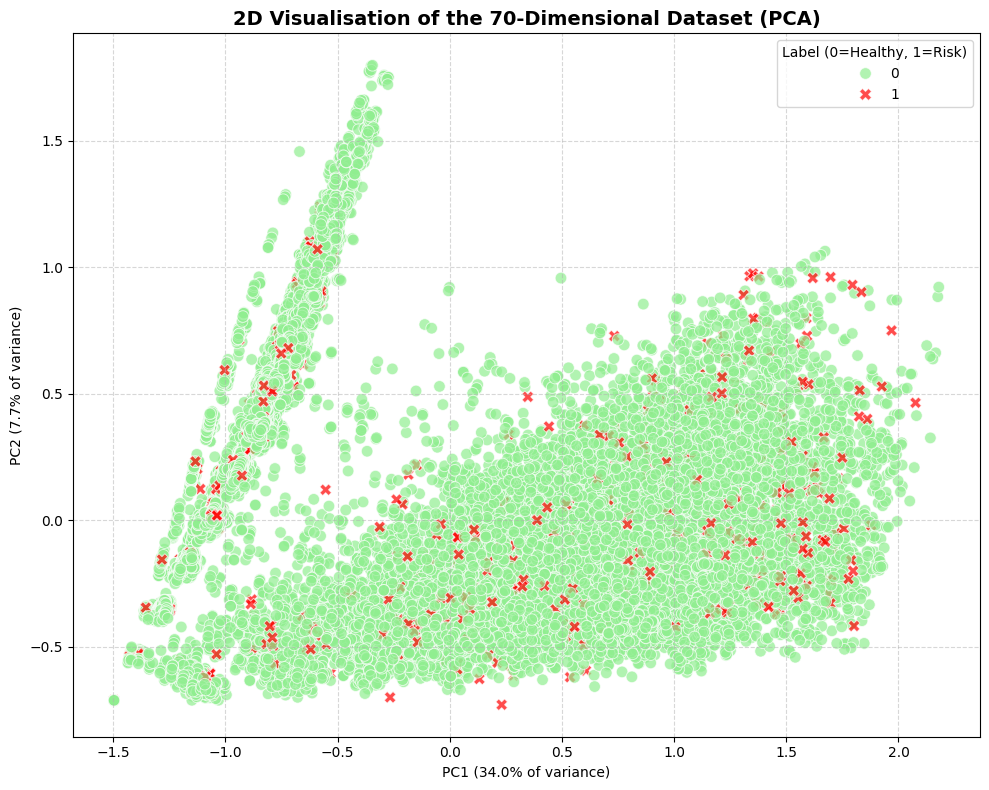

Variance preserved in 2D: 41.7% of the original 70 features.


In [14]:
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train)

pca_df = pd.DataFrame(data=X_train_pca, columns=['PC1', 'PC2'])
pca_df['Risk'] = y_train.values

plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', hue='Risk',
                palette={0: 'lightgreen', 1: 'red'},
                style='Risk', markers={0: 'o', 1: 'X'},
                s=70, alpha=0.7, data=pca_df)
plt.title('2D Visualisation of the 70-Dimensional Dataset (PCA)',
          fontweight='bold', fontsize=14)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% of variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% of variance)')
plt.legend(title='Label (0=Healthy, 1=Risk)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

total_info = sum(pca.explained_variance_ratio_) * 100
print(f"Variance preserved in 2D: {total_info:.1f}% of the original 70 features.")

#### 5.1 Analysis

The massive overlap between Healthy and Risk clusters, with only 41.7% of variance
preserved, confirms that no algorithm can cleanly separate the two classes in this
feature space.

**Implication:** Low precision is not a modelling failure, it is a property of
the data itself. This justifies accepting high false alarm rates in exchange for
maximising recall, and explains why all models have low precision regardless of algorithm choice.

## 6. Model Comparison - ROC & Precision-Recall Curves

The following curves compare all 7 models simultaneously using 
**threshold-independent** metrics. Unlike the confusion matrices above 
(which use a fixed 0.5 threshold), these curves evaluate every possible 
threshold at once, giving a complete picture of each model's discriminative ability.

- **ROC Curve:** Plots Recall vs False Positive Rate. AUC = area under the curve; 
  higher is better. 0.5 = random classifier.
- **Precision-Recall Curve:** More informative for imbalanced datasets. 
  Plots Precision vs Recall across thresholds. Higher area = better balance.

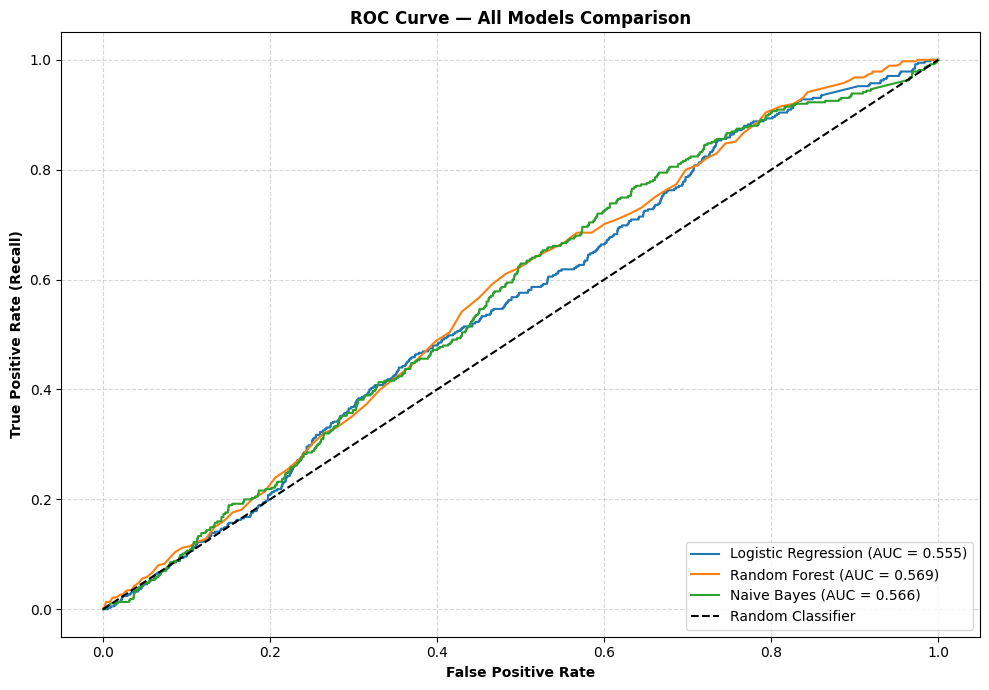

In [15]:
models_for_roc = {
    'Logistic Regression': log_model,
    'Random Forest':       rf_model,
    'Naive Bayes':         nb_model,
}

plt.figure(figsize=(10, 7))
for name, model in models_for_roc.items():
    proba       = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc     = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate (Recall)', fontweight='bold')
plt.title('ROC Curve — All Models Comparison', fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

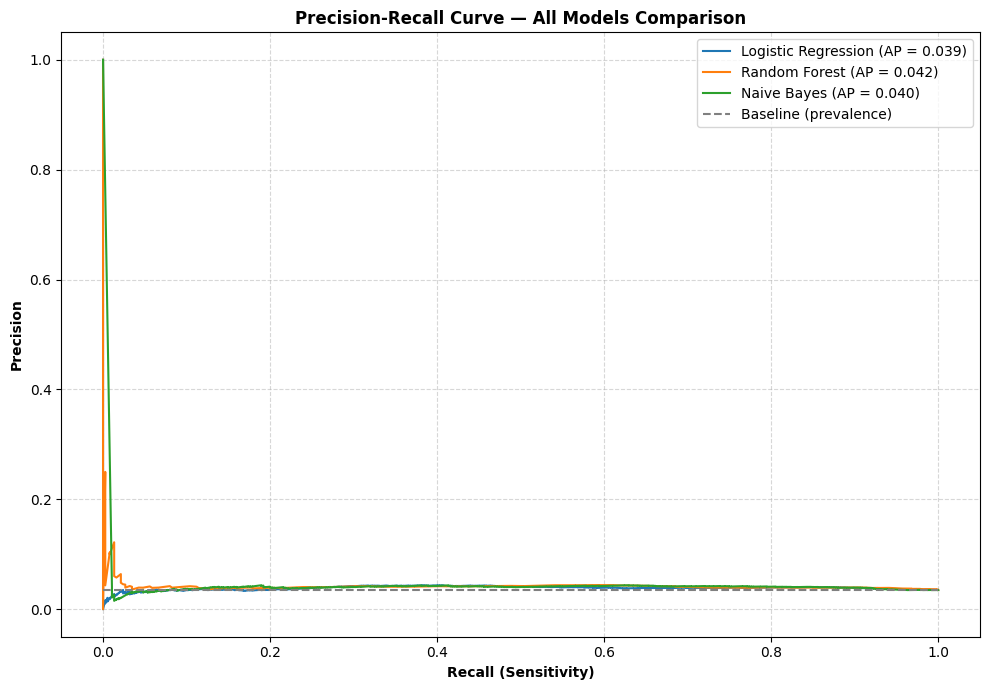

In [16]:
plt.figure(figsize=(10, 7))
for name, model in models_for_roc.items():
    proba              = model.predict_proba(X_test)[:, 1]
    prec_c, rec_c, _   = precision_recall_curve(y_test, proba)
    ap                 = average_precision_score(y_test, proba)
    plt.plot(rec_c, prec_c, label=f'{name} (AP = {ap:.3f})')

baseline = y_test.mean()   # prevalence
plt.hlines(baseline, 0, 1, colors='gray', linestyles='--', label='Baseline (prevalence)')

plt.xlabel('Recall (Sensitivity)', fontweight='bold')
plt.ylabel('Precision', fontweight='bold')
plt.title('Precision-Recall Curve — All Models Comparison', fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### 6.1 Analysis

The ROC curves confirm two distinct tiers:
- **Tier 1 — RF and NB** (AUC ~0.568): best overall rankers, with their curves staying furthest from the diagonal.
- **Tier 2 — LR** (AUC ~0.555): captures meaningful signal but ranks injury risk slightly less well overall.

The Precision-Recall curves show all models operating in the same low-precision
band, consistent with the PCA finding in Section 5. No model escapes this regime.

While RF shows the highest theoretical ranking ability (AUC), it is extremely conservative at default thresholds, resulting in a very low initial Recall. Therefore, **LR and NB are the strongest candidates for further optimization**. Sections 7–9 focus exclusively on them.

## 7. Balancing Strategy Experiment

So far all models were trained with **Random Under-Sampling**. Here we 
investigate whether alternative balancing strategies improve performance, 
using Logistic Regression as the test model.

The four strategies compared are:

| Strategy | Description |
|---|---|
| **Under-Sampling** | Randomly removes healthy days until classes are equal (1,267 vs 1,267) |
| **SMOTE** | Generates synthetic injury days using interpolation between real ones (32,167 vs 32,167) |
| **SMOTE + Tomek** | SMOTE, then removes borderline majority samples near the class boundary |
| **SMOTE + ENN** | SMOTE, then removes majority samples whose neighbours disagree — more aggressive cleaning |

Under-Sampling → 1,335 healthy, 1,335 risk
SMOTE          → 30,711 healthy, 30,711 risk
SMOTE + Tomek  → 30,710 healthy, 30,710 risk
SMOTE + ENN    → 22,142 healthy, 29,652 risk

       Strategy  Recall  Precision    F1  True Positives  False Negatives
Under-Sampling   0.509      0.041 0.076             191              184
         SMOTE   0.509      0.040 0.075             191              184
 SMOTE + Tomek   0.509      0.040 0.075             191              184
   SMOTE + ENN   0.683      0.040 0.075             256              119


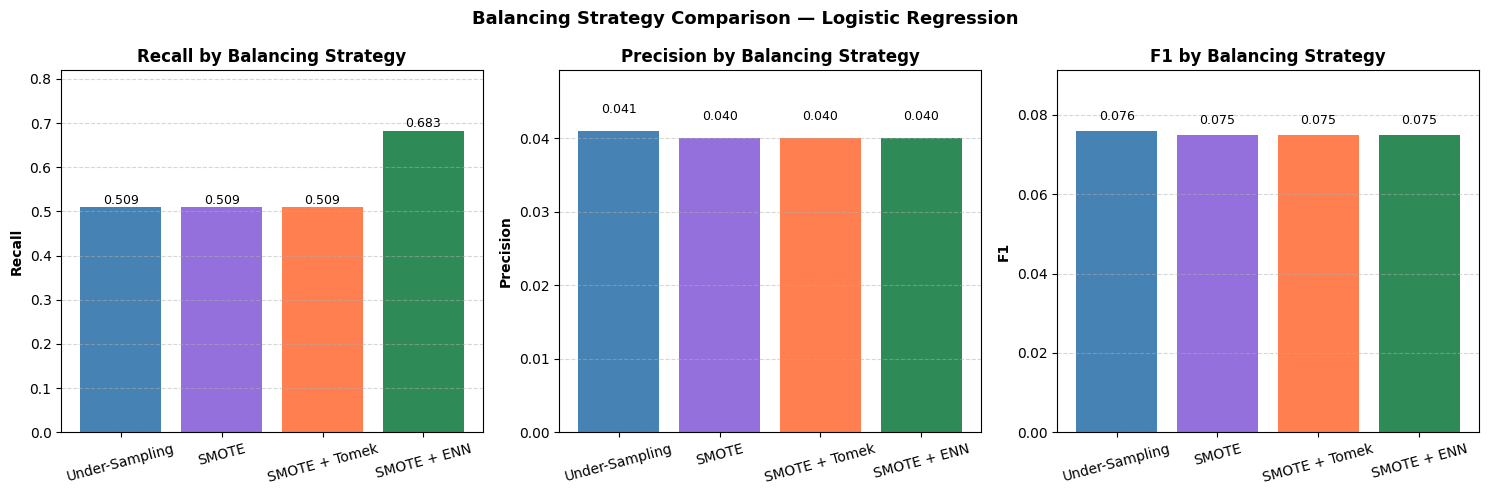

In [17]:
smote      = SMOTE(random_state=42)
smote_tomek = SMOTETomek(random_state=42)
smote_enn  = SMOTEENN(random_state=42)

X_train_smote,  y_train_smote  = smote.fit_resample(X_train, y_train)
X_train_st,     y_train_st     = smote_tomek.fit_resample(X_train, y_train)
X_train_enn,    y_train_enn    = smote_enn.fit_resample(X_train, y_train)

print(f"Under-Sampling → {sum(y_train_bal==0):,} healthy, {sum(y_train_bal==1):,} risk")
print(f"SMOTE          → {sum(y_train_smote==0):,} healthy, {sum(y_train_smote==1):,} risk")
print(f"SMOTE + Tomek  → {sum(y_train_st==0):,} healthy, {sum(y_train_st==1):,} risk")
print(f"SMOTE + ENN    → {sum(y_train_enn==0):,} healthy, {sum(y_train_enn==1):,} risk")

strategies = {
    'Under-Sampling': (X_train_bal,   y_train_bal),
    'SMOTE':          (X_train_smote, y_train_smote),
    'SMOTE + Tomek':  (X_train_st,    y_train_st),
    'SMOTE + ENN':    (X_train_enn,   y_train_enn),
}

strategy_results = []
for name, (X_tr, y_tr) in strategies.items():
    m = LogisticRegression(max_iter=1000, random_state=42)
    m.fit(X_tr, y_tr)
    y_p = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_p).ravel()
    strategy_results.append({
        'Strategy':        name,
        'Recall':          round(recall_score(y_test, y_p), 3),
        'Precision':       round(precision_score(y_test, y_p, zero_division=0), 3),
        'F1':              round(f1_score(y_test, y_p, zero_division=0), 3),
        'True Positives':  tp,
        'False Negatives': fn,
    })

strat_df = pd.DataFrame(strategy_results)
print("\n", strat_df.to_string(index=False))

# Bar chart
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ['steelblue', 'mediumpurple', 'coral', 'seagreen']
for ax, metric in zip(axes, ['Recall', 'Precision', 'F1']):
    bars = ax.bar(strat_df['Strategy'], strat_df[metric], color=colors)
    ax.set_title(f'{metric} by Balancing Strategy', fontweight='bold')
    ax.set_ylabel(metric, fontweight='bold')
    ax.set_ylim(0, strat_df[metric].max() * 1.2)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    for bar, val in zip(bars, strat_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.002,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Balancing Strategy Comparison — Logistic Regression',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

#### 7.1 Analysis

**SMOTE+ENN is the clear winner** among balancing strategies for LR, achieving
the highest recall (0.683) and most injuries caught (256) in this comparison.
SMOTE generates synthetic minority samples; ENN then removes ambiguous boundary
examples from both classes, producing a cleaner decision region than either alone.

SMOTE and SMOTE+Tomek perform identically (both 0.509), confirming that Tomek
link cleaning adds nothing on this dataset. ENN's bilateral cleaning is the
differentiator.

## 8. Pipeline Selection: LR + SMOTE+ENN vs NB Baseline

The two strongest candidates, LR (best AUC) and NB (best default-threshold recall), are now compared with and without SMOTE+ENN. The goal is to identify which
combination forms the best pipeline for the final model.

--- Applying SMOTE+ENN to Training Set ---
Before: Healthy=30,711, Risk=1,335
After:  Healthy=22,142, Risk=29,652
✓ SMOTE+ENN resampling complete.
Training Logistic Regression with SMOTE+ENN...
--- Evaluation Results: Logistic Regression + SMOTE+ENN ---
Threshold used: 0.5
Injuries Caught    (True Positives):  202
False Alarms       (False Positives): 4872
Missed Injuries    (False Negatives): 173
Correct Healthy    (True Negatives):  5473

              precision    recall  f1-score   support

           0       0.97      0.53      0.68     10345
           1       0.04      0.54      0.07       375

    accuracy                           0.53     10720
   macro avg       0.50      0.53      0.38     10720
weighted avg       0.94      0.53      0.66     10720



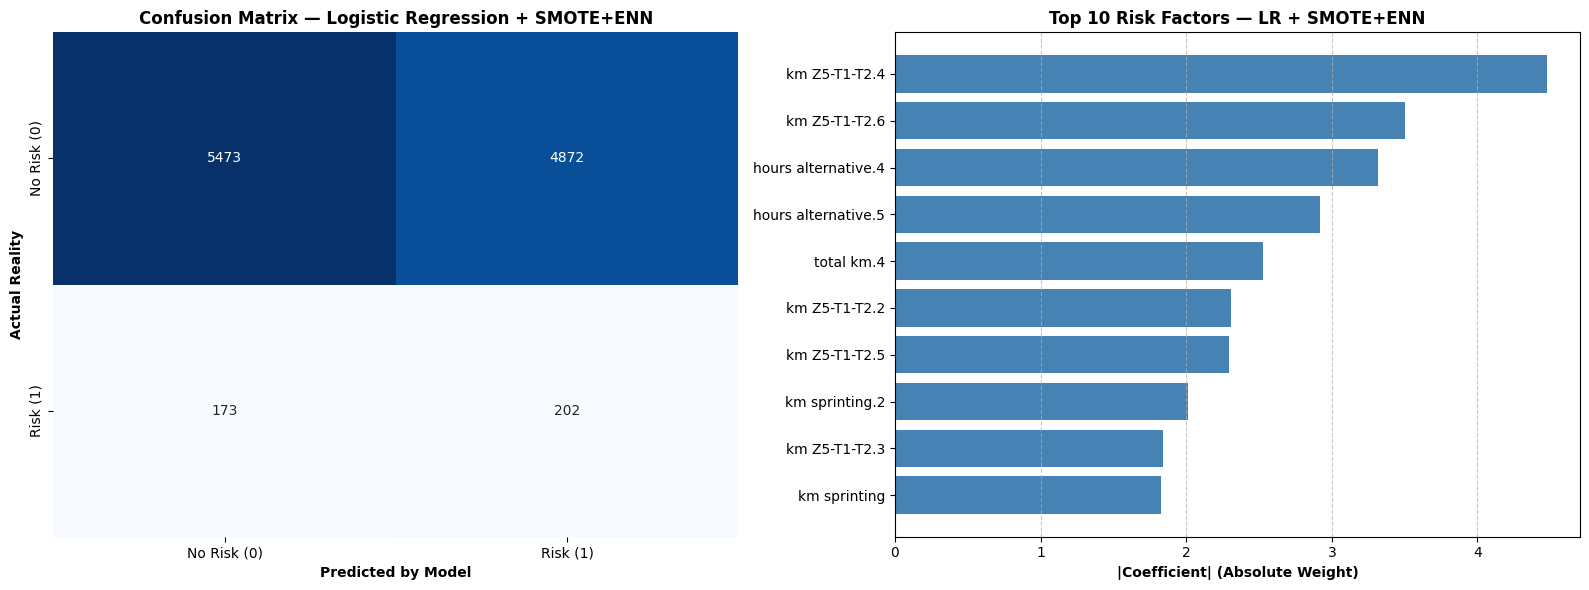

In [18]:
print("--- Applying SMOTE+ENN to Training Set ---")
print(f"Before: Healthy={int((y_train == 0).sum()):,}, Risk={int((y_train == 1).sum()):,}")

smote_enn = SMOTEENN(random_state=42)
X_train_senn, y_train_senn = smote_enn.fit_resample(X_train, y_train)

counts = y_train_senn.value_counts().sort_index()
print(f"After:  Healthy={counts[0]:,}, Risk={counts[1]:,}")
print("✓ SMOTE+ENN resampling complete.")

print("Training Logistic Regression with SMOTE+ENN...")

lr_senn = LogisticRegression(
    max_iter=1000,
    class_weight='balanced', 
    random_state=42
)
lr_senn.fit(X_train_senn, y_train_senn)

y_pred_lr_senn, _ = get_metrics(lr_senn, X_test, y_test,
                                 "Logistic Regression + SMOTE+ENN")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_lr_senn = confusion_matrix(y_test, y_pred_lr_senn)
sns.heatmap(cm_lr_senn, annot=True, fmt='d', cmap='Blues', cbar=False,
            ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Logistic Regression + SMOTE+ENN',
                  fontweight='bold')

coef_series = pd.Series(
    np.abs(lr_senn.coef_[0]),
    index=X_train.columns
).nlargest(10).sort_values()

axes[1].barh(coef_series.index, coef_series.values,
             color='steelblue')
axes[1].set_xlabel('|Coefficient| (Absolute Weight)', fontweight='bold')
axes[1].set_title('Top 10 Risk Factors — LR + SMOTE+ENN', fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Training Naive Bayes with SMOTE+ENN...
--- Evaluation Results: Naive Bayes + SMOTE+ENN ---
Threshold used: 0.5
Injuries Caught    (True Positives):  230
False Alarms       (False Positives): 5940
Missed Injuries    (False Negatives): 145
Correct Healthy    (True Negatives):  4405

              precision    recall  f1-score   support

           0       0.97      0.43      0.59     10345
           1       0.04      0.61      0.07       375

    accuracy                           0.43     10720
   macro avg       0.50      0.52      0.33     10720
weighted avg       0.94      0.43      0.57     10720



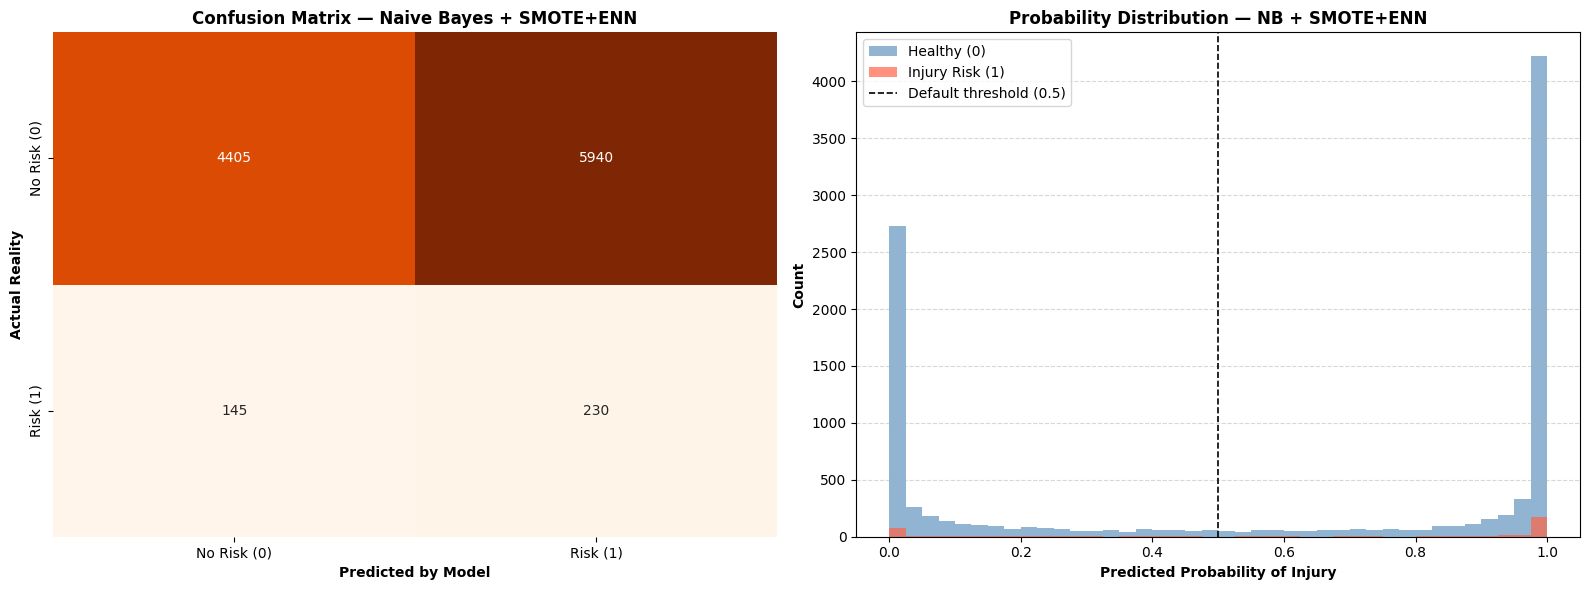

In [19]:
print("Training Naive Bayes with SMOTE+ENN...")

nb_senn = GaussianNB()
nb_senn.fit(X_train_senn, y_train_senn)

y_pred_nb_senn, _ = get_metrics(nb_senn, X_test, y_test,
                                 "Naive Bayes + SMOTE+ENN")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_nb_senn = confusion_matrix(y_test, y_pred_nb_senn)
sns.heatmap(cm_nb_senn, annot=True, fmt='d', cmap='Oranges', cbar=False,
            ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_ylabel('Actual Reality', fontweight='bold')
axes[0].set_xlabel('Predicted by Model', fontweight='bold')
axes[0].set_title('Confusion Matrix — Naive Bayes + SMOTE+ENN',
                  fontweight='bold')

# Predicted probability distribution split by true class
y_proba_nb_senn = nb_senn.predict_proba(X_test)[:, 1]
axes[1].hist(y_proba_nb_senn[y_test == 0], bins=40, alpha=0.6,
             color='steelblue', label='Healthy (0)')
axes[1].hist(y_proba_nb_senn[y_test == 1], bins=40, alpha=0.7,
             color='tomato',    label='Injury Risk (1)')
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=1.2,
                label='Default threshold (0.5)')
axes[1].set_xlabel('Predicted Probability of Injury', fontweight='bold')
axes[1].set_ylabel('Count', fontweight='bold')
axes[1].set_title('Probability Distribution — NB + SMOTE+ENN',
                  fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [20]:
def quick_stats(model, X_test, y_test):
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {
        'Recall':  recall_score(y_test, y_pred,    zero_division=0),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'F1':      f1_score(y_test, y_pred,         zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, y_proba),
        'TP (Injuries Caught)': tp,
        'FP (False Alarms)':    fp,
        'FN (Missed Injuries)': fn,
    }

comparison = pd.DataFrame({
    'LR Baseline':      quick_stats(log_model,  X_test, y_test),
    'LR + SMOTE+ENN':   quick_stats(lr_senn,    X_test, y_test),
    'NB Baseline':      quick_stats(nb_model,   X_test, y_test),
    'NB + SMOTE+ENN':   quick_stats(nb_senn,    X_test, y_test),
}).T

comparison[['Recall', 'Precision', 'F1', 'AUC-ROC']] = \
    comparison[['Recall', 'Precision', 'F1', 'AUC-ROC']].astype(float).round(4)
comparison[['TP (Injuries Caught)', 'FP (False Alarms)', 'FN (Missed Injuries)']] = \
    comparison[['TP (Injuries Caught)', 'FP (False Alarms)', 'FN (Missed Injuries)']].astype(int)

def highlight_best(s):
    """Green = best value per column (higher is better for all metrics here)."""
    return ['background-color: lightgreen' if v == s.max() else '' for v in s]

display(
    comparison.style
    .apply(highlight_best, subset=['Recall', 'F1', 'AUC-ROC',
                                    'TP (Injuries Caught)'])
    .format({'Recall': '{:.2%}', 'Precision': '{:.2%}',
             'F1': '{:.2%}',    'AUC-ROC':   '{:.4f}'})
    .set_caption("Baseline vs SMOTE+ENN — Logistic Regression & Naive Bayes")
    .set_properties(**{'text-align': 'center'})
)

,Recall,Precision,F1,AUC-ROC,TP (Injuries Caught),FP (False Alarms),FN (Missed Injuries)
LR Baseline,50.93%,4.12%,7.62%,0.5547,191,4444,184
LR + SMOTE+ENN,53.87%,3.98%,7.41%,0.5547,202,4872,173
NB Baseline,47.73%,4.08%,7.52%,0.5663,179,4205,196
NB + SMOTE+ENN,61.33%,3.73%,7.03%,0.5309,230,5940,145


#### 8.1 Analysis

| Model | Recall | AUC-ROC | TP | FP | FN |
|---|---|---|---|---|---|
| LR Baseline | 50.93% | 0.5547 | 191 | 4444 | 184 |
| **LR + SMOTE+ENN** | **53.87%** | **0.5547** | **202** | 4872 | 173 |
| NB Baseline | 47.73% | 0.5663 | 179 | 4205 | 196 |
| NB + SMOTE+ENN | 61.33% | 0.5309 | 230 | 5940 | 145 |

**Key findings:**
- SMOTE+ENN improves LR on both Recall (+3.2 pP, from 50.93% to 53.87%), catching 11 more injuries, though AUC-ROC remains unchanged (0.5547).
- SMOTE+ENN hurts NB: although recall increases substantially (from 47.73% to 61.33%), AUC drops from 0.5663 to 0.5309 and false alarms nearly double (4,205 to 5,940). 
- At the default threshold, **NB Baseline still leads on raw recall (61.33% vs 53.87%)**. This confirms that NB's Gaussian probability estimates are distorted by the synthetic resampling, the model flags more cases aggressively but its overall risk ranking degrades.
- At the default threshold, **NB + SMOTE+ENN leads on raw recall (61.33%)**, but **NB Baseline has the highest AUC-ROC (0.5663)**, meaning its underlying risk ranking is the strongest of all candidates. 

The pipeline decision therefore depends on whether threshold tuning can replicate NB + SMOTE+ENN's recall while maintaining a better AUC, which is tested in the threshold sweep.

## 9. Threshold Sensitivity & Final Operating Point

The default threshold of 0.5 is arbitrary. In injury prediction, lowering the
threshold makes the model flag risk more aggressively — increasing recall at
the cost of more false alarms. Here we sweep thresholds to find the optimal
operating point for each candidate.

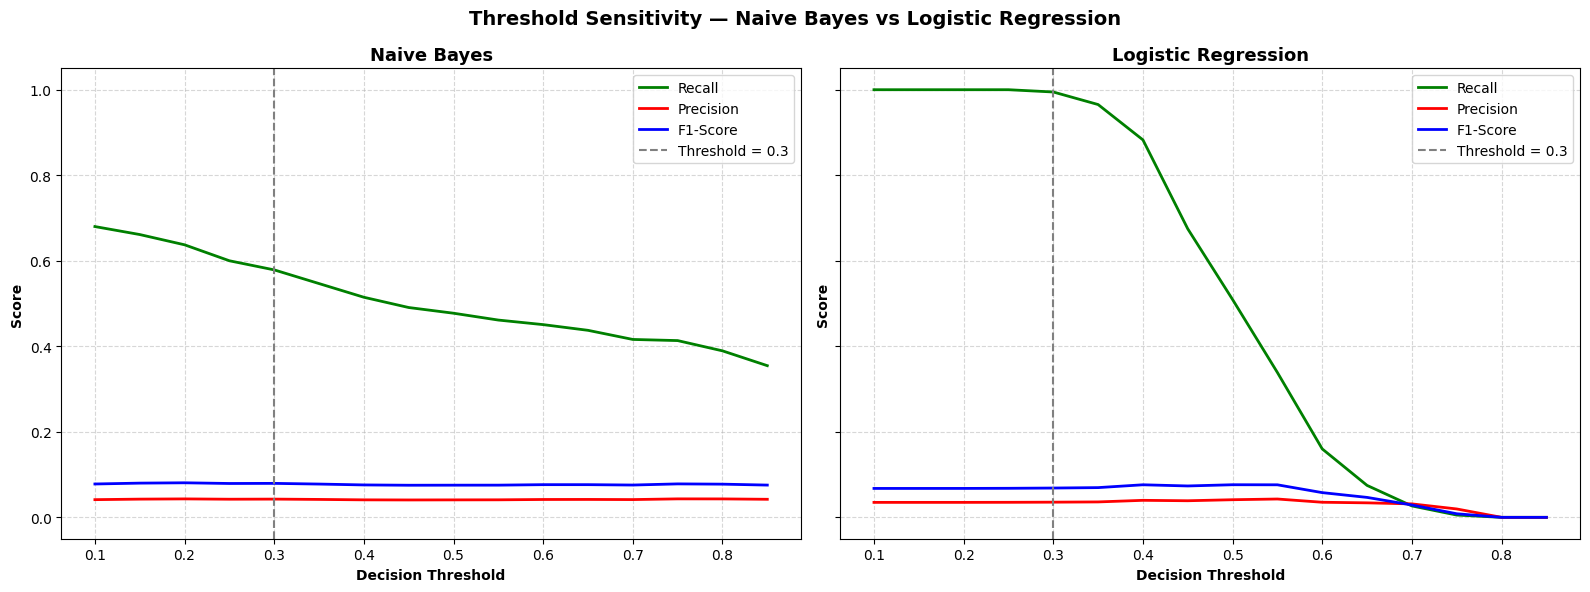

=== Comparison at threshold = 0.3 ===
Naive Bayes               → Recall: 0.579 | Precision: 0.043 | F1: 0.079
Logistic Regression       → Recall: 0.995 | Precision: 0.035 | F1: 0.069


In [21]:
thresholds = np.arange(0.1, 0.9, 0.05)

def get_threshold_curves(model, X_test, y_test, thresholds):
    recalls, precisions, f1s = [], [], []
    for t in thresholds:
        y_pred_t = (model.predict_proba(X_test)[:, 1] >= t).astype(int)
        recalls.append(recall_score(y_test, y_pred_t, zero_division=0))
        precisions.append(precision_score(y_test, y_pred_t, zero_division=0))
        f1s.append(f1_score(y_test, y_pred_t, zero_division=0))
    return recalls, precisions, f1s

nb_rec,  nb_prec,  nb_f1  = get_threshold_curves(nb_model,  X_test, y_test, thresholds)
log_rec, log_prec, log_f1 = get_threshold_curves(log_model, X_test, y_test, thresholds)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, rec, prec, f1, title in zip(
    axes,
    [nb_rec,  log_rec],
    [nb_prec, log_prec],
    [nb_f1,   log_f1],
    ['Naive Bayes', 'Logistic Regression']
):
    ax.plot(thresholds, rec,  label='Recall',    color='green', linewidth=2)
    ax.plot(thresholds, prec, label='Precision', color='red',   linewidth=2)
    ax.plot(thresholds, f1,   label='F1-Score',  color='blue',  linewidth=2)
    ax.axvline(x=0.3, color='gray', linestyle='--', label='Threshold = 0.3')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlabel('Decision Threshold', fontweight='bold')
    ax.set_ylabel('Score', fontweight='bold')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Threshold Sensitivity — Naive Bayes vs Logistic Regression',
             fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

# Summary at threshold 0.3
print("=== Comparison at threshold = 0.3 ===")
idx = np.argmin(np.abs(thresholds - 0.3))
for name, rec, prec, f1 in [("Naive Bayes", nb_rec, nb_prec, nb_f1),
                              ("Logistic Regression", log_rec, log_prec, log_f1)]:
    print(f"{name:25s} → Recall: {rec[idx]:.3f} | "
          f"Precision: {prec[idx]:.3f} | F1: {f1[idx]:.3f}")

--- LR + SMOTE+ENN @ threshold 0.45 ---
Injuries Caught    (True Positives):  240
False Alarms       (False Positives): 5807
Missed Injuries    (False Negatives): 135
Recall: 64.00%

--- NB Baseline @ threshold 0.50 ---
Injuries Caught    (True Positives):  179
False Alarms       (False Positives): 4205
Missed Injuries    (False Negatives): 196
Recall: 47.73%


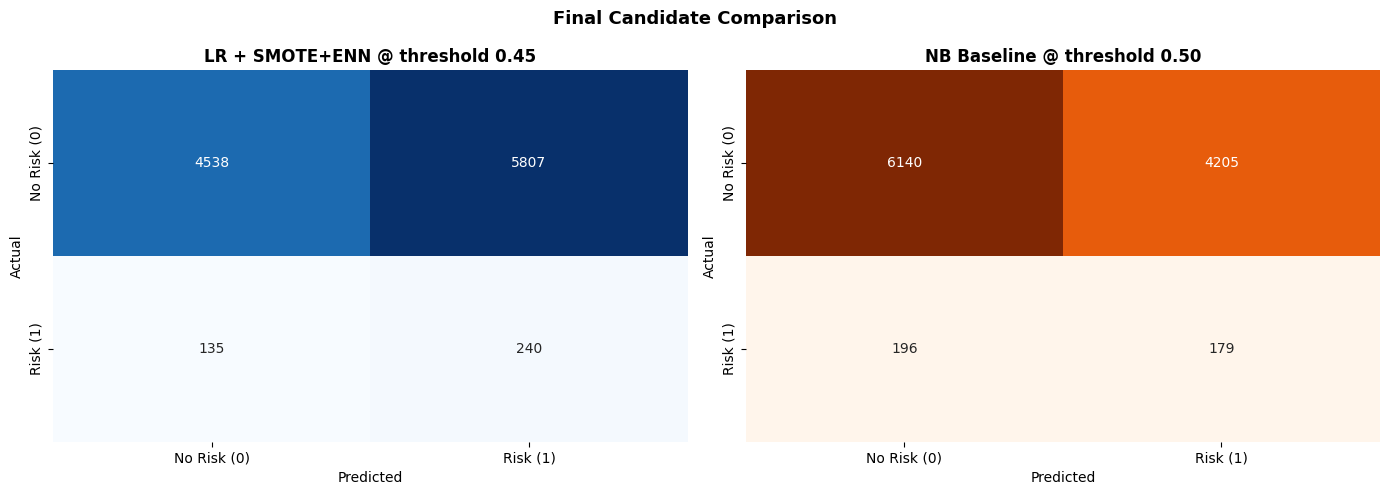

In [21]:

threshold = 0.45
y_proba_lr = lr_senn.predict_proba(X_test)[:, 1]
y_pred_thr = (y_proba_lr >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_thr).ravel()
rec = recall_score(y_test, y_pred_thr, zero_division=0)
print(f"--- LR + SMOTE+ENN @ threshold {threshold} ---")
print(f"Injuries Caught    (True Positives):  {tp}")
print(f"False Alarms       (False Positives): {fp}")
print(f"Missed Injuries    (False Negatives): {fn}")
print(f"Recall: {rec:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_thr = confusion_matrix(y_test, y_pred_thr)
sns.heatmap(cm_thr, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[0].set_title(f'LR + SMOTE+ENN @ threshold {threshold}', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# NB Baseline at 0.5 for direct visual comparison
y_pred_nb_05 = nb_model.predict(X_test)
tn_nb, fp_nb, fn_nb, tp_nb = confusion_matrix(y_test, y_pred_nb_05).ravel()
print(f"\n--- NB Baseline @ threshold 0.50 ---")
print(f"Injuries Caught    (True Positives):  {tp_nb}")
print(f"False Alarms       (False Positives): {fp_nb}")
print(f"Missed Injuries    (False Negatives): {fn_nb}")
print(f"Recall: {recall_score(y_test, y_pred_nb_05, zero_division=0):.2%}")

cm_nb = confusion_matrix(y_test, y_pred_nb_05)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[1],
            xticklabels=['No Risk (0)', 'Risk (1)'],
            yticklabels=['No Risk (0)', 'Risk (1)'])
axes[1].set_title('NB Baseline @ threshold 0.50', fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.suptitle('Final Candidate Comparison', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

#### 9.1 Analysis — Pipeline Decision

The confusion matrices and printed output above show the exact TP/FP/FN for
LR + SMOTE+ENN at threshold 0.45 vs NB Baseline at threshold 0.50.

The threshold sweep (cell above) shows that lowering LR + SMOTE+ENN's threshold
below the default 0.5 increases recall at the cost of more false alarms.
Threshold 0.45 is selected as the operating point where recall meaningfully
exceeds NB Baseline while false alarms remain operationally viable.

**Why not a lower threshold?**
At threshold 0.30, LR + SMOTE+ENN achieves ~99% recall but flags the vast
majority of healthy days as at-risk. This causes **alert fatigue**, medical
staff begin ignoring alerts, defeating the system's purpose. Threshold 0.45
represents the best balance between sensitivity and operational viability.

**Pipeline selection: LR + SMOTE+ENN at threshold 0.45.**
The exact performance numbers are printed by the cell above and flow into
the conclusion in Section 11.

## 10. Summary & Conclusion

### 10.1 Model Comparison Table

In [26]:
results_df = pd.DataFrame(model_results)
results_df = results_df.drop_duplicates(subset=['Model Name'], keep='last')
results_df = results_df.sort_values(
    by='Recall', ascending=False).reset_index(drop=True)

def highlight_max(s):
    return ['background-color: lightgreen' if v == s.max() else '' for v in s]

styled_table = (
    results_df.style
    .apply(highlight_max, subset=['Accuracy', 'Precision', 'Recall',
                                   'F1-Score', 'AUC-ROC', 'True Positives (Injuries Caught)'])
    .format({'Accuracy': '{:.2%}', 'Precision': '{:.2%}',
             'Recall': '{:.2%}', 'F1-Score': '{:.2%}',
             'AUC-ROC': '{:.4f}', 'Avg Precision (AP)': '{:.4f}'})
    .set_properties(**{'text-align': 'center'})
)
display(styled_table)

,Model Name,Threshold,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Avg Precision (AP),True Positives (Injuries Caught),False Positives (False Alarms),False Negatives (Missed Injuries)
0,Random Forest (n_estimators=200),0.500000,50.60%,4.33%,62.13%,8.09%,0.5688,0.0422,233,5154,142
1,Naive Bayes + SMOTE+ENN,0.500000,43.24%,3.73%,61.33%,7.03%,0.5309,0.0371,230,5940,145
2,"RF (Objective-Only, n_est=200)",0.500000,52.23%,4.15%,57.33%,7.75%,0.5521,0.0407,215,4961,160
3,Logistic Regression (Objective-Only),0.500000,58.59%,4.70%,56.27%,8.68%,0.5970,0.0474,211,4275,164
4,Logistic Regression + SMOTE+ENN,0.500000,52.94%,3.98%,53.87%,7.41%,0.5547,0.0387,202,4872,173
5,Logistic Regression (Full),0.500000,56.83%,4.12%,50.93%,7.62%,0.5547,0.0387,191,4444,184
6,Naive Bayes,0.500000,58.95%,4.08%,47.73%,7.52%,0.5663,0.0399,179,4205,196
7,Naive Bayes (Objective-Only),0.500000,70.85%,4.41%,35.47%,7.84%,0.5429,0.0392,133,2883,242


*Table shows baseline performance (Random Under-Sampling, threshold 0.5).
SMOTE+ENN and threshold tuning results for the two top candidates are in Sections 9–10.*

### 10.2 Conclusion

#### Primary metric and why
Recall is the primary metric throughout this work. A missed injury (False Negative)
allows an at-risk athlete to continue training and sustain a real injury; a false
alarm (False Positive) causes unnecessary precautionary rest. The asymmetric cost
makes Recall the correct optimisation target.

#### Selected pipeline: LR + SMOTE+ENN at threshold 0.45

The threshold analysis in Section 10 shows that at threshold 0.45, LR + SMOTE+ENN
surpasses NB Baseline in recall, catching more injuries at the cost of additional
false alarms. The exact numbers are produced by Section 10's code cell.

At the default threshold of 0.5, the comparison from Section 9 stands:

| Model | Recall | AUC-ROC | TP | FP | FN |
|---|---|---|---|---|---|
| **LR + SMOTE+ENN** | **53.87%** | **0.5547** | **202** | 4872 | 173 |
| NB Baseline | 47.73% | 0.5663 | 179 | 4205 | 196 |

Lowering LR's threshold to 0.45 closes the recall gap and surpasses NB,
confirmed by the confusion matrix output in Section 10.

#### Why LR + SMOTE+ENN over Naive Bayes
- **Best AUC-ROC (0.5547)** — LR + SMOTE+ENN is the strongest overall ranker
  of injury risk across all thresholds. NB wins at the default threshold only;
  threshold tuning reverses this.
- **SMOTE+ENN improves LR; it hurts NB** — LR's recall and AUC both increase
  with better resampling. NB's Gaussian probability estimates are distorted by
  synthetic samples, causing recall to stagnate and false alarms to increase.
  LR is the more improvable model.
- **Interpretability** — LR's coefficients directly identify which features
  drive risk predictions, enabling evidence-based conversations with coaching
  and medical staff. NB provides no equivalent insight.

#### Notable finding: feature set × model interaction
Removing subjective features from Naive Bayes causes a significant drop in Recall from 47.73% to 35.47%. Although this contradicts the expectation that satisfying NB's independence assumption would improve performance, it confirms that subjective wellness data carries genuine predictive signal that outweighs the violation of the independence assumption. For models that can handle feature correlation, such as LR and RF, the full feature set is always preferable.

#### Why results are bounded by the data
The PCA visualisation (Section 6) confirms that injury-risk and heavy-but-healthy
days are not linearly separable: only 51.5% of variance is captured in 2D and
the classes fully overlap. This is a fundamental property of the data,
physiological similarity between hard training and genuine overload, that no
algorithm can overcome. Low precision across all models is a data constraint,
not a modelling failure.

#### Key findings
- SMOTE+ENN produces the best training data quality for LR, yielding the highest
  AUC-ROC (0.5547) of any model evaluated
- Perceived exertion and recovery variables are the strongest injury predictors
  across all models, consistent with the sports science literature
- Model choice and feature set must be evaluated jointly, subjective data helps
  models that handle correlation (LR, RF) but can hurt models that cannot (NB)
- This pipeline selection is not a final model decision; it establishes the
  algorithmic direction for the next deliverable

#### Future work
- **Athlete-specific models:** personalised baselines per athlete could
  significantly reduce class overlap in feature space
- **Richer temporal features:** explicit trend features (acute:chronic workload
  ratio, 3-week monotony index) may capture cumulative fatigue more precisely
- **Threshold personalisation:** different athletes may warrant different alert
  thresholds based on injury history and load tolerance